# Project 2 — Concrete Compressive Strength
**DSC8307 | Data Mining, Modeling and Analytics | Advent 2026**

**Research question:** How accurately can mixture ingredients and curing age predict compressive strength, and where do models fail?

**Method:** fixed 80/20 train/test split; 5-fold shuffled cross-validation on training data; mean baseline, regularized linear regression, random forest and histogram gradient boosting. Model selection uses CV RMSE only. Holdout test is used once for final reporting. No causal claims are made from observational associations.

In [ ]:
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split,cross_validate,KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.inspection import permutation_importance
SEED=42
path=Path('Concrete_Data.csv')
if not path.exists():path=Path('..')/path
raw=pd.read_csv(path)
raw.columns=['cement','slag','fly_ash','water','superplasticizer','coarse_aggregate','fine_aggregate','age_days','strength_mpa']
print('Shape:',raw.shape,'Duplicates:',raw.duplicated().sum());display(raw.head(),raw.describe().T)
print('Missing:',raw.isna().sum().to_dict())

Shape: (1030, 9) Duplicates: 25


,cement,slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age_days,strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
slag,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
fly_ash,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
water,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplasticizer,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
coarse_aggregate,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
fine_aggregate,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
age_days,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
strength_mpa,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


Missing: {'cement': 0, 'slag': 0, 'fly_ash': 0, 'water': 0, 'superplasticizer': 0, 'coarse_aggregate': 0, 'fine_aggregate': 0, 'age_days': 0, 'strength_mpa': 0}


## Exploratory analysis and preparation
All inputs are numerical and expressed in engineering units. Retain zero quantities: they mean an ingredient is absent, not missing. The data contain potentially repeated mixtures; do not remove rows automatically, as repeated strength measurements can be scientifically meaningful. Median imputation and scaling are fitted inside the training pipeline; scaling is important for regularized linear regression. The random split estimates performance on mixtures similar to those observed; unseen mixture families or curing regimes may generalize worse.

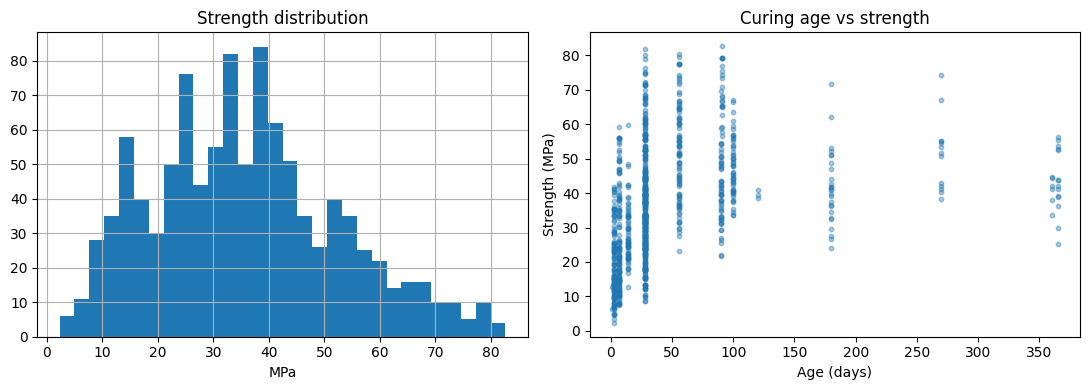

Pearson correlations with strength:


strength_mpa        1.000000
cement              0.497833
superplasticizer    0.366102
age_days            0.328877
slag                0.134824
fly_ash            -0.105753
coarse_aggregate   -0.164928
fine_aggregate     -0.167249
water              -0.289613
Name: strength_mpa, dtype: float64

Train: 824 Test: 206


In [2]:
fig,ax=plt.subplots(1,2,figsize=(11,4));raw.strength_mpa.hist(bins=30,ax=ax[0]);ax[0].set(xlabel='MPa',title='Strength distribution');ax[1].scatter(raw.age_days,raw.strength_mpa,s=10,alpha=.4);ax[1].set(xlabel='Age (days)',ylabel='Strength (MPa)',title='Curing age vs strength');plt.tight_layout();plt.show()
print('Pearson correlations with strength:');display(raw.corr(numeric_only=True)['strength_mpa'].sort_values(ascending=False))
X=raw.drop(columns='strength_mpa');y=raw.strength_mpa
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=SEED)
print('Train:',len(X_train),'Test:',len(X_test))

## Baseline and linear vs nonlinear model comparison
The mean predictor is the reference. Ridge regression is an interpretable regularized linear model; random forest and gradient boosting can capture nonlinear age effects and ingredient interactions. Compare 5-fold CV RMSE (primary, lower is better), MAE, and R². Model choice is based on training-only cross-validation, not the test set.

In [3]:
prep=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
models={
 'Mean baseline':DummyRegressor(strategy='mean'),
 'Ridge (linear)':Pipeline([('prep',prep),('model',Ridge(alpha=10.0))]),
 'Random forest (nonlinear)':Pipeline([('prep',SimpleImputer(strategy='median')),('model',RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=SEED,n_jobs=-1))]),
 'Gradient boosting (nonlinear)':Pipeline([('prep',SimpleImputer(strategy='median')),('model',HistGradientBoostingRegressor(max_iter=200,learning_rate=.07,l2_regularization=1.0,random_state=SEED))])}
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
rows=[]
for name,m in models.items():
 s=cross_validate(m,X_train,y_train,cv=cv,scoring={'rmse':'neg_root_mean_squared_error','mae':'neg_mean_absolute_error','r2':'r2'},n_jobs=1)
 rows.append({'model':name,'CV_RMSE_mean':-s['test_rmse'].mean(),'CV_RMSE_sd':s['test_rmse'].std(),'CV_MAE_mean':-s['test_mae'].mean(),'CV_R2_mean':s['test_r2'].mean()})
comparison=pd.DataFrame(rows).sort_values('CV_RMSE_mean');display(comparison)
selected_name=comparison.iloc[0]['model'];selected=models[selected_name].fit(X_train,y_train)
print('Selected by CV RMSE:',selected_name)

,model,CV_RMSE_mean,CV_RMSE_sd,CV_MAE_mean,CV_R2_mean
3,Gradient boosting (nonlinear),4.827906,0.428902,3.204415,0.916651
2,Random forest (nonlinear),5.462657,0.502358,3.872708,0.893038
1,Ridge (linear),10.654301,0.448812,8.489644,0.595201
0,Mean baseline,16.885284,0.456708,13.582778,-0.011982


Selected by CV RMSE: Gradient boosting (nonlinear)


## Test evaluation and residual diagnostics
Residual = observed minus predicted strength. Inspect systematic patterns across predicted strength, curing age and cement content; report error by age group and strength quartile to identify weaknesses. Quartiles are defined using training-set target cut points to avoid adapting bins to the test outcomes. Small subgroups are less reliable; inspect their sample sizes.

Test RMSE: 4.60100801707369 MAE: 3.0517260098103494 R²: 0.9178469986688743


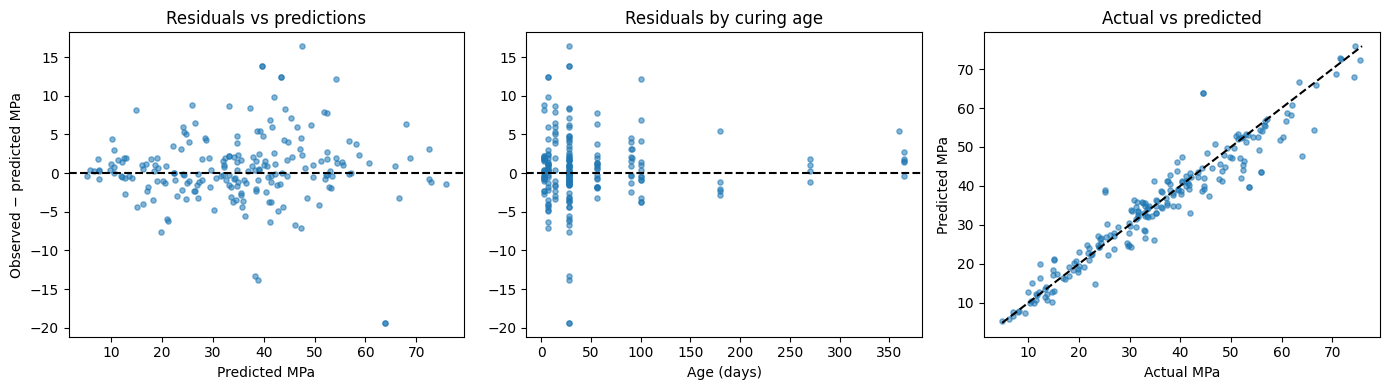


 age_group


,n,MAE,bias
age_group,,,
8–28 days,91,3.711928,0.277622
≤7 days,56,2.744273,0.717048
>90 days,30,2.536293,0.987384
29–90 days,29,2.106965,0.968042



 strength_group


,n,MAE,bias
strength_group,,,
"(45.865, inf]",54,4.149407,3.531611
"(34.084, 45.865]",53,3.297694,-0.254919
"(23.682, 34.084]",49,2.798389,-0.760962
"(-inf, 23.682]",50,1.853774,-0.335923


Ten largest errors:


,actual,predicted,error,absolute_error,age,cement,age_group,strength_group
109,44.519465,63.892961,-19.373496,19.373496,28,313.00,8–28 days,"(34.084, 45.865]"
182,44.523602,63.892961,-19.369359,19.369359,28,312.70,8–28 days,"(34.084, 45.865]"
54,64.017847,47.596293,16.421554,16.421554,28,505.00,8–28 days,"(45.865, inf]"
94,53.524711,39.625211,13.899500,13.899500,28,297.80,8–28 days,"(45.865, inf]"
119,53.524022,39.625211,13.898811,13.898811,28,298.00,8–28 days,"(45.865, inf]"
10,25.096926,38.980049,-13.883123,13.883123,28,313.00,8–28 days,"(23.682, 34.084]"
73,25.103821,38.404919,-13.301098,13.301098,28,312.70,8–28 days,"(23.682, 34.084]"
1,55.895819,43.463269,12.432551,12.432551,7,362.60,≤7 days,"(45.865, inf]"
158,55.895819,43.463269,12.432551,12.432551,7,362.60,≤7 days,"(45.865, inf]"
33,66.424118,54.278711,12.145407,12.145407,100,246.83,>90 days,"(45.865, inf]"


In [4]:
pred=selected.predict(X_test);resid=y_test.to_numpy()-pred
print('Test RMSE:',mean_squared_error(y_test,pred)**.5,'MAE:',mean_absolute_error(y_test,pred),'R²:',r2_score(y_test,pred))
fig,ax=plt.subplots(1,3,figsize=(14,4));ax[0].scatter(pred,resid,alpha=.55,s=14);ax[0].axhline(0,color='black',ls='--');ax[0].set(xlabel='Predicted MPa',ylabel='Observed − predicted MPa',title='Residuals vs predictions');ax[1].scatter(X_test.age_days,resid,alpha=.55,s=14);ax[1].axhline(0,color='black',ls='--');ax[1].set(xlabel='Age (days)',title='Residuals by curing age');ax[2].scatter(y_test,pred,alpha=.55,s=14);lims=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())];ax[2].plot(lims,lims,'k--');ax[2].set(xlabel='Actual MPa',ylabel='Predicted MPa',title='Actual vs predicted');plt.tight_layout();plt.show()
diagnostic=pd.DataFrame({'actual':y_test.to_numpy(),'predicted':pred,'error':resid,'absolute_error':np.abs(resid),'age':X_test.age_days.to_numpy(),'cement':X_test.cement.to_numpy()})
diagnostic['age_group']=pd.cut(diagnostic.age,bins=[0,7,28,90,np.inf],labels=['≤7 days','8–28 days','29–90 days','>90 days'],include_lowest=True)
q=np.unique(np.quantile(y_train,[0,.25,.5,.75,1]));diagnostic['strength_group']=pd.cut(diagnostic.actual,bins=[-np.inf,*q[1:-1],np.inf],include_lowest=True)
for group in ['age_group','strength_group']:
 print('\n',group);display(diagnostic.groupby(group,observed=True).agg(n=('absolute_error','size'),MAE=('absolute_error','mean'),bias=('error','mean')).sort_values('MAE',ascending=False))
print('Ten largest errors:');display(diagnostic.sort_values('absolute_error',ascending=False).head(10))

## Robustness and feature interpretation
Permutation importance measures the increase in holdout error when a predictor is shuffled. It is a *predictive* measure, not causal effect; correlated mixture ingredients may share importance. The grouped error table and cross-validation standard deviations are additional diagnostics. A separate external dataset or group-based validation by distinct mix designs would better test deployment robustness.

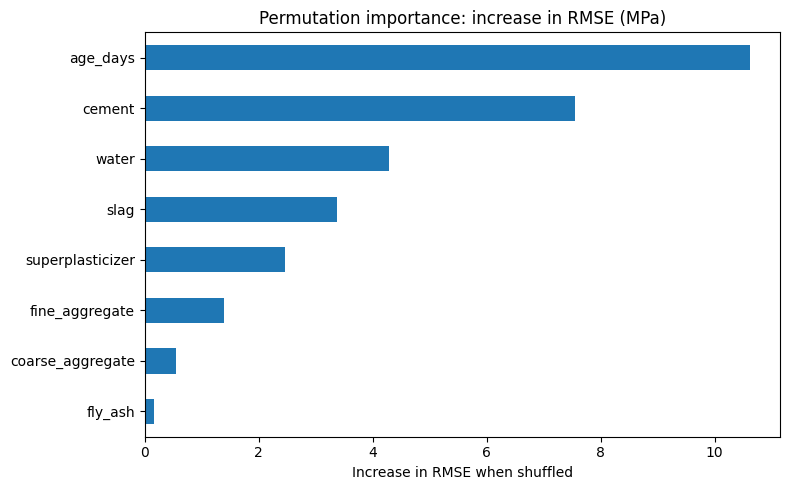

CV vs test RMSE: 4.828 4.601


In [5]:
pi=permutation_importance(selected,X_test,y_test,n_repeats=5,random_state=SEED,scoring='neg_root_mean_squared_error')
importance=pd.Series(pi.importances_mean,index=X.columns).sort_values(ascending=True)
importance.plot.barh(figsize=(8,5),title='Permutation importance: increase in RMSE (MPa)');plt.xlabel('Increase in RMSE when shuffled');plt.tight_layout();plt.show()
print('CV vs test RMSE:',round(float(comparison.iloc[0].CV_RMSE_mean),3),round(mean_squared_error(y_test,pred)**.5,3))

## Does cement association prove the result of changing a mixture?
**No.** A predictive association is not a controlled intervention. Cement, water, admixtures, aggregates, curing time and processing conditions are jointly chosen, so cement content is confounded with other design decisions. Mixture proportions also obey physical constraints: increasing cement while holding all other components constant may change total volume and water–cement ratio. The observed dataset does not randomize cement amounts or capture all production and curing conditions. Model extrapolation outside observed recipes may violate physical feasibility. A defensible intervention claim requires a controlled mixture experiment (vary cement while fixing or explicitly balancing other ingredients, replicate specimens, standardize curing/testing) or an appropriately identified causal design.

## Conclusion
Compare the CV table to determine whether nonlinear approaches improve upon ridge and the mean baseline. Report the held-out RMSE/MAE/R², and use age-group and strength-group residual summaries to locate weak regimes. These are prediction results, not guarantees for new mix designs or causal evidence for altering cement.

**References:** Yeh (1998), *Modeling of strength of high-performance concrete using artificial neural networks*, Cement and Concrete Research 28(12), 1797–1808; scikit-learn User Guide (cross-validation, permutation importance and regression metrics). Dataset notes supplied in `Concrete_Data_README.txt`.